# Accelerating MCMC with Active Subspaces

__Paul G. Constantine__, Department of Applied Mathematics and Statistics, Colorado School of Mines, <paul.constantine@mines.edu>

__Carson Kent__, Institute for Computational and Mathematical Engineering, Stanford University, <crkent@stanford.edu>

__Tan Bui-Thanh__, Department of Aerospace Engineering and Engineering Mechanics, Institute for Computational Engineering and Sciences, University of Texas at Austin, <tanbui@ices.utexas.edu>

__Ryan Howard__ (2016 notebook)

(Affiliations and emails as published in [[1]][R1].)

<br>

This notebook summarizes the active subspace-accelerated Markov chain Monte Carlo (MCMC) of [[1]][R1] and reproduces its two examples (§5) with the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later. It runs in Python 3 with numpy, scipy and matplotlib (see the repository's `requirements.txt`) and takes about five minutes. The long PDE chains are not run here: they are loaded from `pde_mcmc_chains.npz`, which `generate_data.py` writes from saved seeds (see `DATA.md`).

### Introduction

Markov chain Monte Carlo (MCMC) is the primary computational tool used in Bayesian problems (especially inverse problems). The goal of MCMC is to create Markov chains whose limiting distribution is the distribution you'd like to sample from (the posterior distribution of parameters, for example). Standard MCMC is inefficient when the parameter space is high-dimensional or evaluating the likelihood is expensive; exhaustively exploring high-dimensional spaces to find high-likelihood regions or evaluating many expensive likelihoods (from forward models that rely on PDE approximations, for example) can make MCMC prohibitively expensive.

One approach to decreasing the cost of MCMC is to perform it on a low-dimensional subspace of the parameter space. Here we'll achieve this goal by looking for an _active subspace_ based on the negative log-likelihood of the data and the prior distribution of the parameters. If we can find such a subspace, we can construct a function that approximates the posterior distribution in fewer dimensions, increasing the efficiency of the resulting MCMC. Since the active subspace does not depend on the posterior, it can be computed before doing MCMC as a preprocessing step, which is computationally appealing.

### Active Subspaces

Consider a scalar-valued, differentiable function $f(\mathbf x)$ from $R^m$ into $R$ and let $\rho(\mathbf x)$ be a pdf on $\mathbf x$ such that

$$
\int \mathbf x\ \rho\ d\mathbf x = 0,\ \ \ \int\mathbf x\ \mathbf x^T\ \rho\ d\mathbf x = \mathbf I,
$$

where $\mathbf I$ is the $m\times m$ identity matrix. Active subspace methodology is based on the matrix

$$
\mathbf C = \int\nabla f\nabla f^T\ \rho\ d\mathbf x = \mathbf W\Lambda\mathbf W^T,
$$

where $\mathbf W$ is the matrix of eigenvectors and $\Lambda$ is the diagonal matrix of eigenvalues in descending order. The $i^{th}$ eigenvalue quantifies the change of $f$ along the $i^{th}$ eigenvector: $\int(\mathbf w_i^T\ \nabla f)^2\rho\ d\mathbf x = \lambda_i$; if $\lambda_i$ is small, $f$ tends to be relatively constant along $\mathbf w_i$. To define the active subspace, we partition the eigendecomposition as:

$$
\mathbf W = \left[\begin{matrix}\mathbf W_1 & \mathbf W_2\end{matrix}\right],\ \ \Lambda = \left[\begin{matrix}\Lambda_1 & \\ & \Lambda_2\end{matrix}\right],
$$

where $\mathbf W_1$ contains the first $n$ (out of $m$) eigenvectors and $\Lambda_1$ has the first $n$ eigenvalues (this partition will be valid if $\lambda_n > \lambda_{n+1}$). The active subspace is the span of $\mathbf W_1$'s columns; perturbations along these directions tend to change $f$ more than in the orthogonal directions. For any $\mathbf x\in R^m,\ \mathbf x = \mathbf W\mathbf W^T\mathbf x = \mathbf W_1 \mathbf W_1^T \mathbf x + \mathbf W_2\mathbf W_2^T\mathbf x = \mathbf W_1\mathbf y + \mathbf W_2 \mathbf z$. $\mathbf y = \mathbf W_1^T\mathbf x$ are called the active variables and $\mathbf z = \mathbf W_2^T\mathbf x$ the inactive variables. The distribution $\rho(\mathbf x)$ can be written as a joint density of $\mathbf y$ and $\mathbf z$: $\rho(\mathbf x) = \rho(\mathbf W_1\mathbf y + \mathbf W_2 \mathbf z) = \rho(\mathbf y, \mathbf z)$ (if $\rho$ is standard Gaussian, marginal and conditional densities of $\mathbf y$ and $\mathbf z$ will also be standard Gaussian).

If $\lambda_{n+1},\dots,\lambda_m$ are small, we can approximate $f$ as

$$
f(\mathbf x)\approx g(\mathbf y) = \int f(\mathbf W_1\mathbf y + \mathbf W_2\mathbf z)\ \rho(\mathbf z|\mathbf y)\ d\mathbf z.
$$

$g$ is the conditional average of $f$ given $\mathbf y$; if $f$ is relatively constant in $\mathbf z$, we expect this to be a good approximation. The RMSE of this approximation is bounded by

$$
\left(\int\left(f(\mathbf x) - g(\mathbf W_1^T\mathbf x)\right)^2\ \rho\ d\mathbf x\right)^{1/2} \leq C(\lambda_{n+1} + \cdots + \lambda_m)^{1/2},
$$

where $C$ is the Poincaré constant associated with $\rho$ ($C$ = 1 if $\rho$ is standard Gaussian). $g$ is difficult to compute, so we can use simple Monte Carlo integration to approximate it:

$$
g(\mathbf y) \approx \hat g(\mathbf y) = \frac 1 M\sum_{i=1}^M f(\mathbf W_1\mathbf y + \mathbf W_2\mathbf z_i),
$$

where $\{\mathbf z_i\}_{i=1}^M$ are drawn independently from $\rho(\mathbf z|\mathbf y)$. The error bound on the resulting approximation is

$$
\left(\int\left(f(\mathbf x) - \hat g(\mathbf W_1^T\mathbf x)\right)^2\ \rho\ d\mathbf x\right)^{1/2} \leq C(1 + M^{-1/2})(\lambda_{n+1} + \cdots + \lambda_m)^{1/2}.
$$

Of course we can't generally compute the matrix $\mathbf C$ analytically, so we approximate it with simple Monte Carlo: draw $\{\mathbf x_i\}_{i=1}^N$ from $\rho$ and compute $\nabla f(\mathbf x_i)$ for each $i$, then

$$
\mathbf C\approx \hat{\mathbf C} = \frac 1 N\sum_{i=1}^N \nabla f(\mathbf x_i)\ \nabla f(\mathbf x_i)^T = \hat{\mathbf W}\hat\Lambda\hat{\mathbf W}^T.
$$

The estimated active and inactive variables are $\hat{\mathbf y} = \hat{\mathbf W}_1^T\mathbf x$ and $\hat{\mathbf z} = \hat{\mathbf W}_2^T\mathbf x$, respectively. The error in the estimated subspace, $\varepsilon = ||\hat{\mathbf W}_1^T\mathbf W_2||$, is inversely proportional to $\lambda_{n} - \lambda_{n+1}$, and we can define our approximation as

$$
f(\mathbf x) \approx g_\varepsilon(\hat{\mathbf W}_1^T\mathbf x) = \int f(\hat{\mathbf W}_1\hat{\mathbf y} + \hat{\mathbf W}_2\hat{\mathbf z}) \rho(\hat{\mathbf z}|\hat{\mathbf y})d\hat{\mathbf z}
$$

with error bound

$$
\left(\int\left(f(\mathbf x) - g_\varepsilon(\hat{\mathbf W}_1^T\mathbf x)\right)^2\ \rho\ d\mathbf x\right)^{1/2} \leq C\left(\varepsilon(\lambda_{1} + \cdots + \lambda_n)^{1/2} + (\lambda_{n+1} + \cdots + \lambda_m)^{1/2}\right).
$$

We can approximate $g_\varepsilon$ using simple Monte Carlo in the same way we approximate $g$:

$$
g_\varepsilon(\hat{\mathbf y})\approx \hat{g}_\varepsilon(\hat{\mathbf y}) = \frac 1 M\sum_{i=1}^M f(\hat{\mathbf W}_1\hat{\mathbf y} + \hat{\mathbf W}_2\hat{\mathbf z}_i),
$$

which has error bound

$$
\left(\int\left(f(\mathbf x) - \hat g_\varepsilon(\hat{\mathbf W}_1^T\mathbf x)\right)^2\ \rho\ d\mathbf x\right)^{1/2} \leq C(1+M^{-1/2})\left(\varepsilon(\lambda_{1} + \cdots + \lambda_n)^{1/2} + (\lambda_{n+1} + \cdots + \lambda_m)^{1/2}\right).
$$

In summary, we have a function, $f$, that we'd like to approximate, and we do this in 4 layers: a low-dimensional conditional average, $g(\mathbf y)$; an approximated conditional average, $\hat g(\mathbf y)$; a conditional average using estimated eigenvectors, $g_\varepsilon(\hat{\mathbf y})$; and an approximated conditional average using estimated eigenvectors, $\hat g_\varepsilon(\hat{\mathbf y})$. $\hat g_\varepsilon$ will be used in the majority of cases since the others rely on knowing non-approximated values of quantities that are nearly impossible to derive analytically.

### Estimating a Bayesian Posterior

Consider the Bayesian inverse problem involving an additive noise model: $\mathbf d = \mathbf m(\mathbf x) + \mathbf e$, where $\mathbf d$ are the observed data, $\mathbf x$ are the parameters, $\mathbf m$ is a deterministic map (the forward model), and $\mathbf e$ is the noise. Assume $\mathbf m$ is differentiable and $\mathbf e \sim N(\mathbf 0, \sigma^2\mathbf I)$. Then the likelihood function is

$$
\rho_{\text{lik}}(\mathbf d,\ \mathbf x) = \exp\left(\frac{-||\mathbf d - \mathbf m(\mathbf x)||^2}{2\sigma^2}\right)
$$

and by Bayes' Theorem,

$$
\rho_{\text{pos}}(\mathbf x) = c_{\text{pos}}^{-1}\ \rho_{\text{lik}}(\mathbf d,\ \mathbf x)\ \rho_{\text{pri}}(\mathbf x),\ \ \ c_{\text{pos}} = \int\rho_{\text{lik}}(\mathbf d,\ \mathbf x)\ \rho_{\text{pri}}(\mathbf x)\ d\mathbf x.
$$

To identify the active subspace, we choose $f$ to be the negative log-likelihood, or data misfit: $f(\mathbf x) = \frac{1}{2\sigma^2}||\mathbf d - \mathbf m(\mathbf x)||^2$, with gradient $\nabla f(\mathbf x) = \frac{1}{\sigma^2}\nabla\mathbf m(\mathbf x)^T(\mathbf m(\mathbf x) - \mathbf d)$, and $\rho$ to be the prior density of $\mathbf x$: $\rho(\mathbf x) = \rho_{\text{pri}}(\mathbf x)$. Then we can construct an approximation of the posterior as

$$
\rho_{\text{pos}}(\mathbf x)\approx \pi(\mathbf x) = c_\pi^{-1}\exp(-g(\mathbf y))\rho_{\text{pri}}(\mathbf y)\rho_{\text{pri}}(\mathbf z|\mathbf y),\ \ c_\pi = \int\exp(-g(\mathbf W_1^T\mathbf x))\rho_{\text{pri}}(\mathbf x)\ d\mathbf x.
$$

We can substitute $\hat g, g_\varepsilon,$ and $\hat g_\varepsilon$ for $g$ above to get $\hat\pi, \pi_\varepsilon$, and $\hat\pi_\varepsilon$. The Hellinger distances between the true posterior and these $\pi$'s are bounded by the error bounds on $g, \hat g, g_\varepsilon$, and $\hat g_\varepsilon$ above, multiplied by $L$, where

$$
L^2 = \frac 1 8\left[\left(\int\exp(-f)\rho_{\text{pri}}d\mathbf x\right)\left(\exp\left(-\int f\rho_{\text{pri}}d\mathbf x\right)\right)\right]^{-1/2}.
$$

For example, $H(\rho_{\text{pos}},\hat\pi_\varepsilon) \leq L\,C(1+M^{-1/2})\left(\varepsilon(\lambda_1 + \cdots + \lambda_n)^{1/2} + (\lambda_{n+1} + \cdots + \lambda_m)^{1/2}\right)$ ([[1]][R1], Theorem 3.1).

### Applying Active Subspaces to MCMC

The first step in applying active subspaces to MCMC is to compute the active subspace using Monte Carlo, as described above, gaining estimates for $\mathbf W_1$ and $\Lambda$. If there is a large gap in the eigenvalues and small values after this gap, there may be an exploitable low-dimensional subspace. If these conditions are present, we can apply the following MCMC algorithm ([[1]][R1], Algorithm 1):

1. Pick an initial value, $\hat{\mathbf y}_1$, and compute $\hat g_\varepsilon(\hat{\mathbf y}_1)$. Set $k = 1$.
2. Draw $\hat{\mathbf y}'$ from a symmetric proposal distribution centered at $\hat{\mathbf y}_k$.
3. Compute $\hat g_\varepsilon(\hat{\mathbf y}')$, with $M$ new draws of $\hat{\mathbf z}$.
4. Compute the acceptance ratio $\gamma =  \min\left(1, \frac{\exp(-\hat g_\varepsilon(\hat{\mathbf y}'))\rho_{\text{pri}}(\hat{\mathbf y}')}{\exp(-\hat g_\varepsilon(\hat{\mathbf y}_k))\rho_{\text{pri}}(\hat{\mathbf y}_k)}\right)$.
5. Draw $t$ from a Unif(0, 1) distribution.
6. If $t \leq \gamma$, set $\hat{\mathbf y}_{k+1} = \hat{\mathbf y}'$ (and keep $\hat g_\varepsilon(\hat{\mathbf y}')$ as $\hat g_\varepsilon(\hat{\mathbf y}_{k+1})$), otherwise set $\hat{\mathbf y}_{k+1} = \hat{\mathbf y}_k$.
7. Increment $k$ and repeat from step 2.

This algorithm is performing Metropolis-Hastings on the estimated active variables $\hat{\mathbf y}$. The value $\hat g_\varepsilon(\hat{\mathbf y}_k)$ at the current state is kept from the step that accepted it, so each step requires only the $M$ forward model evaluations of step 3, whereas standard Metropolis-Hastings requires 1 evaluation per step. While this increases the number of forward model evaluations per step by a factor of $M$, the exponential nature of dimension growth can make dimension reduction through active subspaces plenty worthwhile. To transform the resulting set $\{\hat{\mathbf y}_k\}$ to the original input space, for each $k$, draw $\{\hat{\mathbf z}_{k,l}\}_{l=1}^P$ from $\rho_{\text{pri}}(\hat{\mathbf z}|\hat{\mathbf y}_k)$ and compute $\mathbf x_{k,l} = \hat{\mathbf W}_1\hat{\mathbf y}_k + \hat{\mathbf W}_2\hat{\mathbf z}_{k,l}$. This does not require any forward model evaluations and we expect lower correlation among the $\mathbf x_{k,l}$ compared to standard MCMC since the $\hat{\mathbf z}$'s are drawn independently.

**The variant used in this notebook.** The code that produced the results of [[1]][R1] (and this notebook's 2016 version) does not keep $\hat g_\varepsilon(\hat{\mathbf y}_k)$: at every step it computes $\hat g_\varepsilon$ afresh, with new draws of $\hat{\mathbf z}$, at both the current state $\hat{\mathbf y}_k$ and the proposal $\hat{\mathbf y}'$, which costs $2M$ forward model evaluations per step. We use that variant for the PDE example, so that the results are comparable with [[1]][R1]. Because $\hat g_\varepsilon$ is a noisy estimate, recomputing it makes the sampler an approximate (noisy) Metropolis-Hastings method: its chain is not an exact sampler of $\hat\pi_\varepsilon$, or of any density we can write down, although for small noise it is close to $\pi_\varepsilon$. Algorithm 1 as printed, which keeps $\hat g_\varepsilon$ with the state, avoids the second set of evaluations, but when $\hat g_\varepsilon$ is noisy its chain sticks at states whose estimate came out low (see `DATA.md` for this example). For the quadratic model below, $\hat g_\varepsilon$ comes from a deterministic quadrature rule, and the two variants give the same chain.

The samplers are in `as_mcmc.py`: `random_walk_metropolis` (standard Metropolis-Hastings on $\mathbf x$, which we call _vanilla_ MCMC) and `ActiveSubspaceMCMC` (Metropolis-Hastings on $\hat{\mathbf y}$, with `recompute=True` for the variant above and `recompute=False` for Algorithm 1 as printed, and the reconstruction of $\mathbf x$). Both assume a standard Gaussian prior and do the acceptance test with logarithms.

### References:

[[1]][R1] P.G. Constantine, C. Kent, and T. Bui-Thanh. _Accelerating Markov chain Monte Carlo with active subspaces_. SIAM J. Sci. Comput., 38(5):A2779–A2805, 2016. doi:10.1137/15M1042127

[[2]][R2] P.G. Constantine, E. Dow, and Q. Wang. _Active subspace methods in theory and practice: applications to kriging surfaces_. SIAM J. Sci. Comput., 36(4):A1500–A1524, 2014. doi:10.1137/130916138

[[3]][R3] J.M. Flegal, M. Haran, and G.L. Jones. _Markov chain Monte Carlo: can we trust the third significant figure?_ Statist. Sci., 23(2):250–260, 2008. doi:10.1214/08-STS257

[[4]][R4] C. Andrieu and G.O. Roberts. _The pseudo-marginal approach for efficient Monte Carlo computations_. Ann. Statist., 37(2):697–725, 2009. doi:10.1214/07-AOS574

[R1]: https://doi.org/10.1137/15M1042127
[R2]: https://doi.org/10.1137/130916138
[R3]: https://doi.org/10.1214/08-STS257
[R4]: https://doi.org/10.1214/07-AOS574

### Acknowledgments

This material is based upon work supported by the U.S. Department of Energy Office of Science, Office of Advanced Scientific Computing Research, Applied Mathematics program under Award Number DE-SC-0011077, and by the Defense Advanced Research Projects Agency's Enabling Quantification of Uncertainty in Physical Systems program.

### A two-parameter quadratic model

We'll now demonstrate active subspace-accelerated MCMC on the two examples from [[1]][R1].

The first example is a two-parameter quadratic model: $\mathbf x = [x_1,\ x_2]^T$ with a standard Gaussian prior, and

$$
\mathbf m(\mathbf x) = \frac 1 2\mathbf x^T\mathbf A\mathbf x,\ \ \ \mathbf A = \mathbf Q\left[\begin{matrix}1 & \\ & \epsilon\end{matrix}\right]\mathbf Q^T,\ \ \ \mathbf Q = \frac 1 2\left[\begin{matrix}\sqrt 2 & \sqrt 2 \\ -\sqrt 2 & \sqrt 2\end{matrix}\right].
$$

We use $\epsilon = .01$ ($\mathbf m(\mathbf x)$ with $\epsilon$ close to 1 doesn't have an active subspace), noise standard deviation $\sigma = .1$ in the likelihood, and a single data point $d = .9$. The misfit and its gradient are

$$
f(\mathbf x) = \frac{(d - \mathbf m(\mathbf x))^2}{2\sigma^2},\ \ \ \nabla f(\mathbf x) = \frac{\mathbf m(\mathbf x) - d}{\sigma^2}\,\mathbf A\mathbf x.
$$

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
import active_subspaces as ac

from as_mcmc import ActiveSubspaceMCMC, batch_means_se, random_walk_metropolis

t_start = time.perf_counter()
rng = np.random.default_rng(2016)   # the only source of randomness in this notebook, except the
                                    # generator's saved seeds used to recheck the stored chains


LEVELS = np.array([.02, .1, .25, .5, .75, .9])   # contour levels, as fractions of the peak density


def density(samples, lims, h, smooth):
    """Histogram on a grid of spacing h, smoothed by a Gaussian of standard deviation `smooth`
    (a binned Gaussian kernel density estimate). samples: (N,) or (N, 2)."""
    samples = np.asarray(samples).reshape(len(samples), -1)
    edges = [np.arange(lo, hi + h / 2, h) for lo, hi in lims]
    H, _ = np.histogramdd(samples, bins=edges, density=True)
    centres = [(e[1:] + e[:-1]) / 2 for e in edges]
    return centres, gaussian_filter(H, smooth / h, mode='constant')

In [2]:
Q = .5*np.array([[np.sqrt(2), np.sqrt(2)], [-np.sqrt(2), np.sqrt(2)]])
eps = .01
A = Q @ np.diag([1, eps]) @ Q.T
d_quad = .9      # the data
sigma = .1       # noise standard deviation


def m_quad(X):
    """Forward model, X of shape (..., 2)."""
    return .5*np.einsum('...i,ij,...j->...', X, A, X)


def f_quad(X):
    """Misfit."""
    return (d_quad - m_quad(X))**2 / (2*sigma**2)


def grad_f_quad(X):
    """Gradient of the misfit, shape (..., 2)."""
    return ((m_quad(X) - d_quad) / sigma**2)[..., None] * (X @ A)


space2 = ac.Gaussian.reference(2)

We approximate the subspace by Monte Carlo with $N = 1000$ gradient samples drawn from the prior, and bootstrap the eigenvalues and the subspace error. [[1]][R1] Fig. 5.1(a) instead computes $\mathbf C$ with a tensor-product Gauss–Hermite rule with 50 points in each dimension; we print those eigenvalues too.

Eigenvector signs are arbitrary. v1 makes each eigenvector's largest component positive; we use `ac.orient` to make the first component positive instead, the 2016 package's rule, here and for the PDE example.

Monte Carlo (N = 1000): eigenvalues 2.199e+04, 0.611; n = 1; w1 = [ 0.7073 -0.7069]
50 x 50 Gauss-Hermite:  eigenvalues 1.866e+04, 0.648 (paper Fig. 5.1(a): about 2e4 and 0.7)


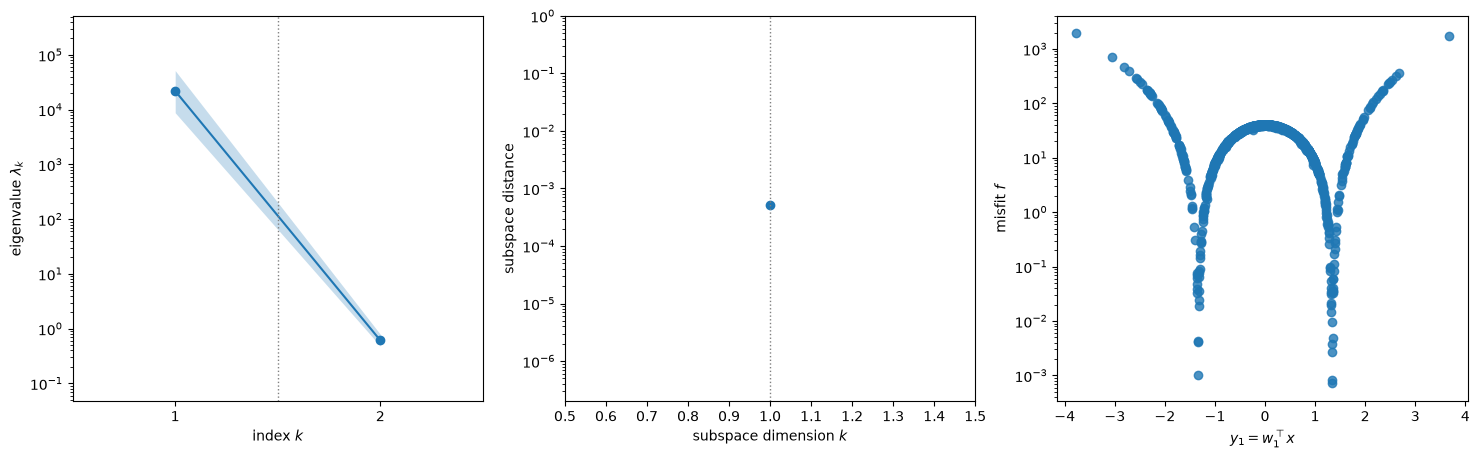

In [3]:
X_grad2 = rng.standard_normal((1000, 2))
sub2 = ac.active_subspace(space=space2, grads=grad_f_quad(X_grad2), nboot=500, rng=rng)
sub2 = ac.orient(sub2, by='reference', reference=np.eye(2)[:, [0, 0]], columns=2)

p50, w50 = np.polynomial.hermite_e.hermegauss(50)
X_gh = np.array(np.meshgrid(p50, p50, indexing='ij')).reshape(2, -1).T
w_gh = np.outer(w50, w50).ravel() / (2*np.pi)
sub2_gh = ac.active_subspace(space=space2, grads=grad_f_quad(X_gh), quad_weights=w_gh)
print(f'Monte Carlo (N = 1000): eigenvalues {sub2.eigenvalues[0]:.4g}, {sub2.eigenvalues[1]:.3g}; '
      f'n = {sub2.n}; w1 = {np.round(sub2.W[:, 0], 4)}')
print(f'50 x 50 Gauss-Hermite:  eigenvalues {sub2_gh.eigenvalues[0]:.4g}, {sub2_gh.eigenvalues[1]:.3g} '
      f'(paper Fig. 5.1(a): about 2e4 and 0.7)')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ac.plotting.plot_eigenvalues(sub2, interval='minmax', ax=axes[0])
ac.plotting.plot_subspace_errors(sub2, interval='minmax', ax=axes[1])
ac.plotting.plot_sufficient_summary(sub2, X=X_grad2, f=f_quad(X_grad2), qoi_label='misfit $f$', ax=axes[2])
axes[2].set_yscale('log')
plt.show()

The two eigenvalues differ by more than four orders of magnitude, and the bootstrap subspace error is small: v1's default rule picks $n = 1$, a one-dimensional active subspace. The sufficient summary plot confirms it: the misfit is a tight function of the active variable $\hat y = \hat{\mathbf w}_1^T\mathbf x$, with its minima at two values of $\hat y$ of opposite sign. The Gauss–Hermite eigenvalues agree with [[1]][R1] Fig. 5.1(a).

We now perform standard Metropolis-Hastings MCMC on $\mathbf x$ with a normal proposal centered at the current state and covariance $.5\mathbf I$, for $10^6$ steps from $\mathbf x = [1, 1]^T$, as in [[1]][R1].

vanilla MCMC: 1000000 steps in 12 s, acceptance rate 0.1186 (paper: 12%)


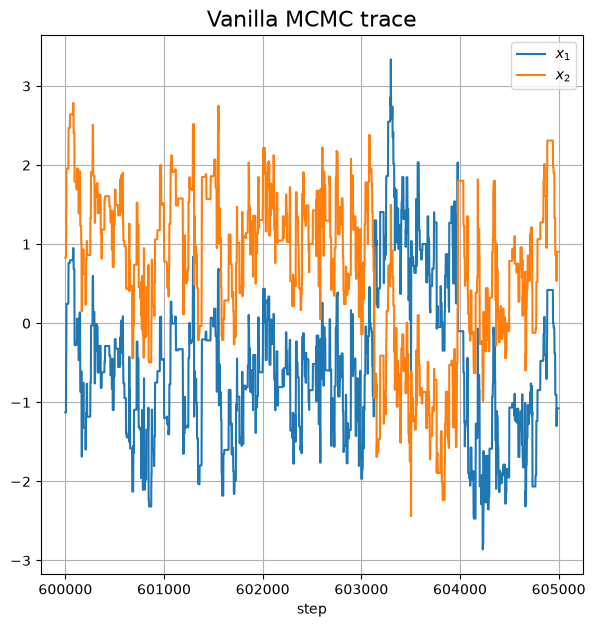

In [4]:
N_quad = 10**6
t0 = time.perf_counter()
X_van2, f_van2, acc_van2 = random_walk_metropolis(lambda x: f_quad(x), np.array([1., 1.]), N_quad,
                                                  np.sqrt(.5), rng)
print(f'vanilla MCMC: {N_quad} steps in {time.perf_counter() - t0:.0f} s, '
      f'acceptance rate {acc_van2.mean():.4f} (paper: 12%)')

steps = np.arange(600_000, 605_000)     # the window of the paper's Fig. 5.2(d)
plt.figure(figsize=(7, 7))
plt.plot(steps, X_van2[steps, 0], steps, X_van2[steps, 1])
plt.grid(True)
plt.xlabel('step')
plt.title('Vanilla MCMC trace', fontsize=16)
plt.legend([r'$x_1$', r'$x_2$'])
plt.show()

We can see significant autocorrelation and cross-correlation in these samples.

Now we perform Metropolis-Hastings on the active variable $\hat y$ ($n = 1$) with $10^5$ steps, one order of magnitude fewer than for vanilla MCMC, from $\hat y = 1$; the proposal is normal with variance $.5$. Here $\hat z$ also has one component, and its conditional density given $\hat y$ is standard Gaussian, so, as in [[1]][R1], we compute $\hat g_\varepsilon(\hat y)$ with a 10-point Gauss–Hermite quadrature rule in $\hat z$ instead of Monte Carlo. Each step then uses 10 forward model evaluations, so the total number of forward model evaluations, $10^6$, is the same as for vanilla MCMC.

In [5]:
sub2_1 = ac.with_dimension(sub2, 1)
p10, w10 = np.polynomial.hermite_e.hermegauss(10)
quad_sampler = ActiveSubspaceMCMC(lambda x: f_quad(x), sub2_1.W1, sub2_1.W2,
                                  z_rule=(p10[:, None], w10 / np.sqrt(2*np.pi)))
t0 = time.perf_counter()
Y2, ghat2, acc_as2 = quad_sampler.sample_active_variables(np.array([1.]), N_quad // 10, 10,
                                                          np.sqrt(.5), rng)
print(f'active subspace MCMC: {N_quad // 10} steps in {time.perf_counter() - t0:.0f} s, '
      f'acceptance rate {acc_as2.mean():.4f} (paper: 13%)')

active subspace MCMC: 100000 steps in 5 s, acceptance rate 0.1343 (paper: 13%)


For each $\hat y$ in our chain, we sample $P = 10$ values of $\hat z$ from the prior and compute $\mathbf x = \hat{\mathbf W}_1\hat y + \hat{\mathbf W}_2 \hat z$, giving us a chain of $10^6$ samples of $\mathbf x$. Below are trace plots of $\mathbf x$ and of $\hat y$, over the windows of [[1]][R1] Fig. 5.2(e) and (f).

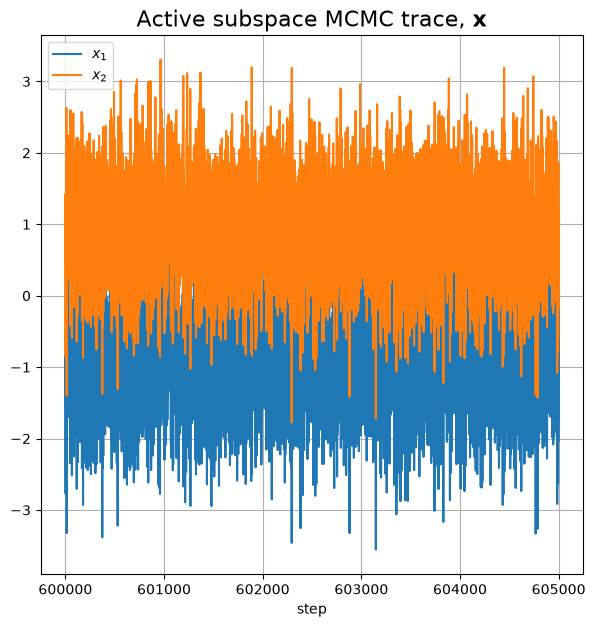

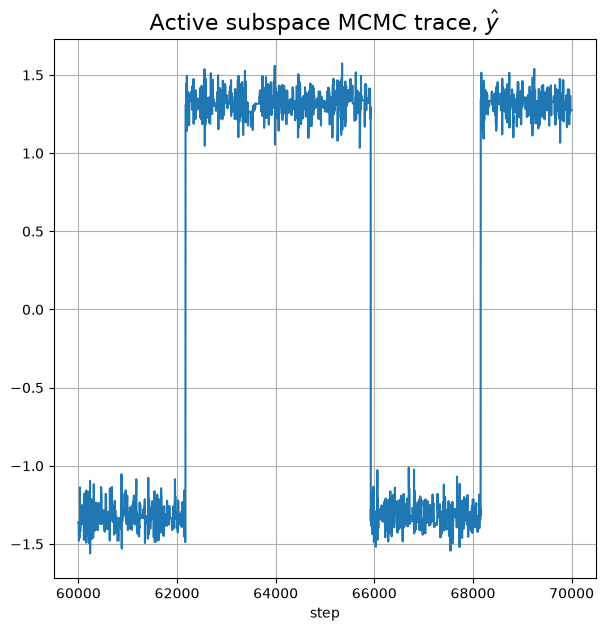

In [6]:
X_as2 = quad_sampler.sample_original_variables(Y2, 10, rng)

plt.figure(figsize=(7, 7))
plt.plot(steps, X_as2[steps, 0], steps, X_as2[steps, 1])
plt.grid(True)
plt.xlabel('step')
plt.title(r'Active subspace MCMC trace, $\mathbf{x}$', fontsize=16)
plt.legend([r'$x_1$', r'$x_2$'])

steps_y = np.arange(60_000, 70_000)
plt.figure(figsize=(7, 7))
plt.plot(steps_y, Y2[steps_y, 0])
plt.grid(True)
plt.xlabel('step')
plt.title(r'Active subspace MCMC trace, $\hat y$', fontsize=16)
plt.show()

There is much less correlation in the samples of $\mathbf x$ than with vanilla MCMC, because the $\hat z$'s are sampled independently. We have a much better chain on $\mathbf x$ for the same number of forward model evaluations by using the active subspace.

Next we compare the posterior densities of both chains on $\mathbf x$, and of the active-variable chain on $\hat y$, using all steps as [[1]][R1] does. The densities are binned Gaussian kernel estimates: a histogram on a grid with spacing 0.02, smoothed by a Gaussian with standard deviation 0.05. (`scipy.stats.gaussian_kde` on $10^6$ points takes minutes, and its default bandwidth, scaled by the spread of both lobes together, blurs the narrow lobes.) We also print the share of samples with $\hat y = \hat{\mathbf w}_1^T\mathbf x > 0$, the lobe on one side of the origin.

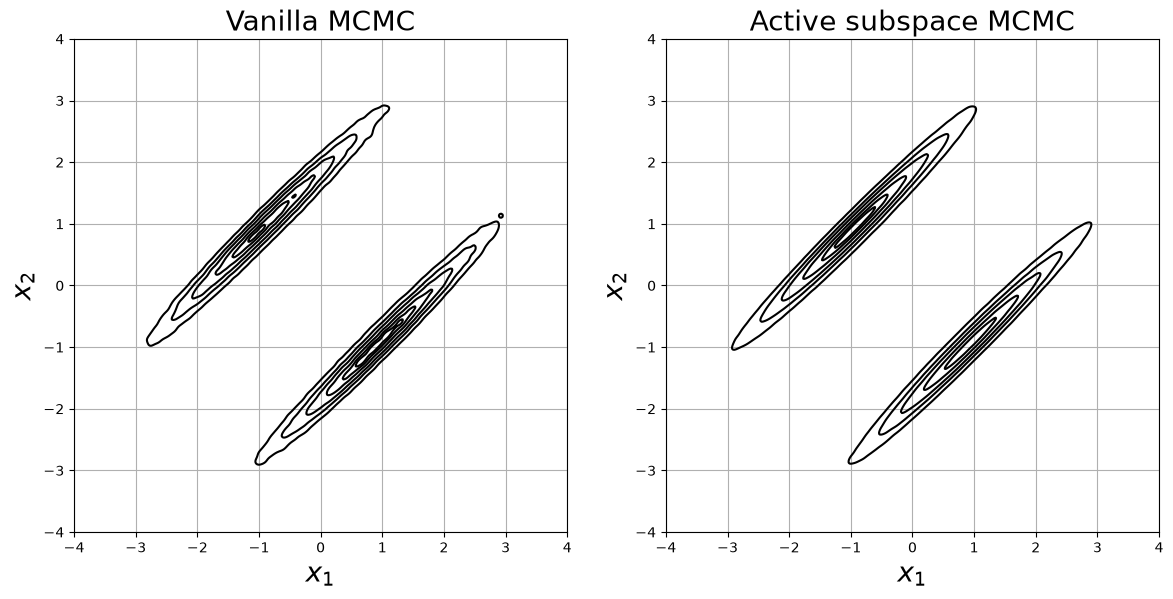

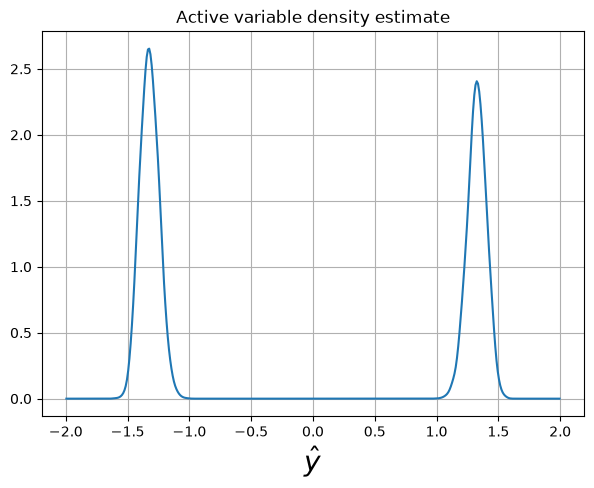

share with w1^T x > 0: vanilla 0.519, active subspace (reconstructed x) 0.467


In [7]:
lims = [(-4, 4), (-4, 4)]
(c1, c2), dens_van = density(X_van2, lims, .02, .05)
_, dens_as = density(X_as2, lims, .02, .05)
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, dens, title in [(axes[0], dens_van, 'Vanilla MCMC'), (axes[1], dens_as, 'Active subspace MCMC')]:
    ax.contour(c1, c2, dens.T, levels=dens.max()*LEVELS, colors="k")
    ax.set_xlim(*lims[0]); ax.set_ylim(*lims[1]); ax.set_aspect('equal')
    ax.grid(True)
    ax.set_xlabel(r'$x_1$', fontsize=20); ax.set_ylabel(r'$x_2$', fontsize=20)
    ax.set_title(title, fontsize=20)

(cy,), dens_y = density(Y2[:, 0], [(-2, 2)], .01, .02)
plt.figure(figsize=(7, 5))
plt.plot(cy, dens_y)
plt.grid(True)
plt.xlabel(r'$\hat y$', fontsize=20)
plt.title('Active variable density estimate')
plt.show()

w1_2 = sub2.W[:, 0]
print(f'share with w1^T x > 0: vanilla {np.mean(X_van2 @ w1_2 > 0):.3f}, '
      f'active subspace (reconstructed x) {np.mean(X_as2 @ w1_2 > 0):.3f}')

Both chains find the two separated lobes of the posterior ([[1]][R1] Fig. 5.1(b)) and put roughly half of their samples in each, and the contours from the active subspace chain agree with those of vanilla MCMC. The density of $\hat y$ has the two narrow peaks of [[1]][R1] Fig. 5.2(c).

### A PDE model with 100 parameters

The second example is a PDE forward model. The PDE is

$$
-\nabla_{\mathbf s}\cdot(a(\mathbf s, \mathbf x)\nabla_{\mathbf s}u) = 1,\ \ \ \mathbf s = [s_1, s_2]^T\in[0, 1]^2,
$$

where $u$ is the solution and $\mathbf s$ are the spatial coordinates, with $u = 0$ on the bottom ($s_2 = 0$), left ($s_1 = 0$) and top ($s_2 = 1$) of the domain, and a zero-flux (homogeneous Neumann) condition on the right ($s_1 = 1$). The log of the coefficient $a$ is a truncated Karhunen–Loève series,

$$
\log(a(\mathbf s, \mathbf x)) = \sum_{i=1}^{m} \sqrt{\sigma_i}\,\phi_i(\mathbf s)\,x_i,
$$

with $m = 100$ terms, where $(\sigma_i, \phi_i)$ are the eigenpairs of the correlation function $\mathcal C(\mathbf s, \mathbf t) = \exp(-\|\mathbf s - \mathbf t\|_1/\beta)$ with $\beta = 0.02$, as in [[1]][R1] eq. (5.5). The eigenpairs are those of the discrete covariance matrix on the $100\times 100$ grid of cell centres, stored in `kl-short.npz` (the same file as in `../Elliptic_PDE_Random_Coefficients`, whose notebook writes this kernel as $\exp(-\|\mathbf s - \mathbf t\|_1/(2\beta))$ with $\beta = .01$). The prior on $\mathbf x$ is standard Gaussian.

The data are noisy observations of $u$ at seven points next to the right boundary: $s_2 = 0.2, 0.3, \dots, 0.8$, at $s_1 = 0.99$, one grid spacing inside the boundary, where [[1]][R1] puts them on it ($s_1 = 1$). The forward model $\mathbf m(\mathbf x)$ returns $u$ at these points. To generate synthetic data, we draw a true value $\mathbf x_{\text{true}}$ from the prior, compute $\mathbf m(\mathbf x_{\text{true}})$, and add Gaussian noise with variance $\sigma^2 = 10^{-4}\|\mathbf m(\mathbf x_{\text{true}})\|^2$, roughly 1% noise, as in [[1]][R1].

**Discretization.** `pde_model.py` (class `PDEMisfit`) solves the PDE with a five-point, vertex-centred finite-volume scheme on a $100\times 100$ grid of cells; [[1]][R1] describes second-order finite differences with 100 points in each dimension. The coefficient $a$ is constant on each cell, and its value on a cell face is the average of the two cells next to it. The unknowns are the $99\times 99$ interior vertices, and the Neumann condition copies the last column of unknowns onto the right boundary (first order). The discrete system is $\mathbf A(\mathbf x)\mathbf u = \mathbf 1$ with $\mathbf A$ symmetric and positive definite. The misfit gradient comes from one adjoint solve, $\mathbf A^T\boldsymbol\lambda = \partial f/\partial\mathbf u$, which reuses the sparse LU factorization of the forward solve, so a misfit and its gradient cost about as much as one solve (timed below). ([[1]][R1] used Wang's `numpad` automatic differentiation package; this code uses only numpy and scipy.)

**Stored chains.** The long chains below take most of an hour of computing (the stored run's times are printed below), so `generate_data.py` runs them once, from saved seeds, and stores them in `pde_mcmc_chains.npz` with everything needed to check them: $\mathbf x_{\text{true}}$, $\mathbf d$, $\sigma^2$, the 1000 points and misfit gradients used for the active subspace, and the eigenvectors $\hat{\mathbf W}$ used by the active-variable chain. We load the file, set up the model with the stored data, and check the model against the stored gradients.

In [8]:
import generate_data
from pde_model import PDEMisfit

z = np.load('pde_mcmc_chains.npz')
model = PDEMisfit()
model.set_data(z['d'], float(z['sig2']))
x_true = z['x_true']
print(f'pde_mcmc_chains.npz: seed {int(z["seed"])}; wall time of the vanilla chain '
      f'{float(z["wall_van"]) / 60:.0f} min (one process), of the active-variable chain '
      f'{float(z["wall_av"]) / 60:.0f} min (misfits on 6 processes)')

obs_true = model.observations(x_true)
print(f'sensors at s1 = {z["sensor_s1"][0]:.2f}, s2 = {np.round(z["sensor_s2"], 2)}')
print(f'sigma^2 = {model.sig2:.4e}; noise ||d - m(x_true)|| / ||m(x_true)|| = '
      f'{np.linalg.norm(model.d - obs_true) / np.linalg.norm(obs_true):.4f}')

x, h, coords = z['X_grad'][0], 1e-5, [0, 1, 2, 5]
g = model.misfit_grad(x)
fd = np.array([(model.misfit(x + h*e) - model.misfit(x - h*e)) / (2*h) for e in np.eye(model.m)[coords]])
print(f'misfit gradient at the first stored point: max relative difference from the stored one '
      f'{np.max(np.abs(g - z["G"][0])) / np.max(np.abs(z["G"][0])):.1e}; '
      f'central FD vs adjoint relative error <= {np.max(np.abs(fd - g[coords]) / np.abs(g[coords])):.1e}')
t0 = time.perf_counter()
for xx in z['X_grad'][:20]:
    model.misfit_grad(xx)
print(f'{(time.perf_counter() - t0) / 20 * 1e3:.0f} ms per misfit and gradient')

pde_mcmc_chains.npz: seed 2779; wall time of the vanilla chain 46 min (one process), of the active-variable chain 22 min (misfits on 6 processes)
sensors at s1 = 0.99, s2 = [0.2 0.3 0.4 0.5 0.6 0.7 0.8]
sigma^2 = 6.2996e-06; noise ||d - m(x_true)|| / ||m(x_true)|| = 0.0278


misfit gradient at the first stored point: max relative difference from the stored one 0.0e+00; central FD vs adjoint relative error <= 1.1e-07


24 ms per misfit and gradient


Now we compute the active subspace from the $N = 1000$ stored misfit gradients, which `generate_data.py` computed at prior samples. The default dimension rule in v1 (the largest gap $\lambda_n - \lambda_{n+1}$) picks $n = 1$ here; like [[1]][R1], we choose $n = 2$, which leaves only $\lambda_3, \dots, \lambda_{100}$ in the error bound. We check that the eigenvectors equal the stored ones, which the active-variable chain used.

default rule: n = 1; chosen: n = 2
eigenvalues 1-4: [1794.8  139.3   27.4   12.1]; ratios lambda_1/lambda_2 = 12.9, lambda_2/lambda_3 = 5.1
|cos| between recomputed and stored w1, w2: [1. 1.]; ||W1^T W1 - I|| = 1.2e-15


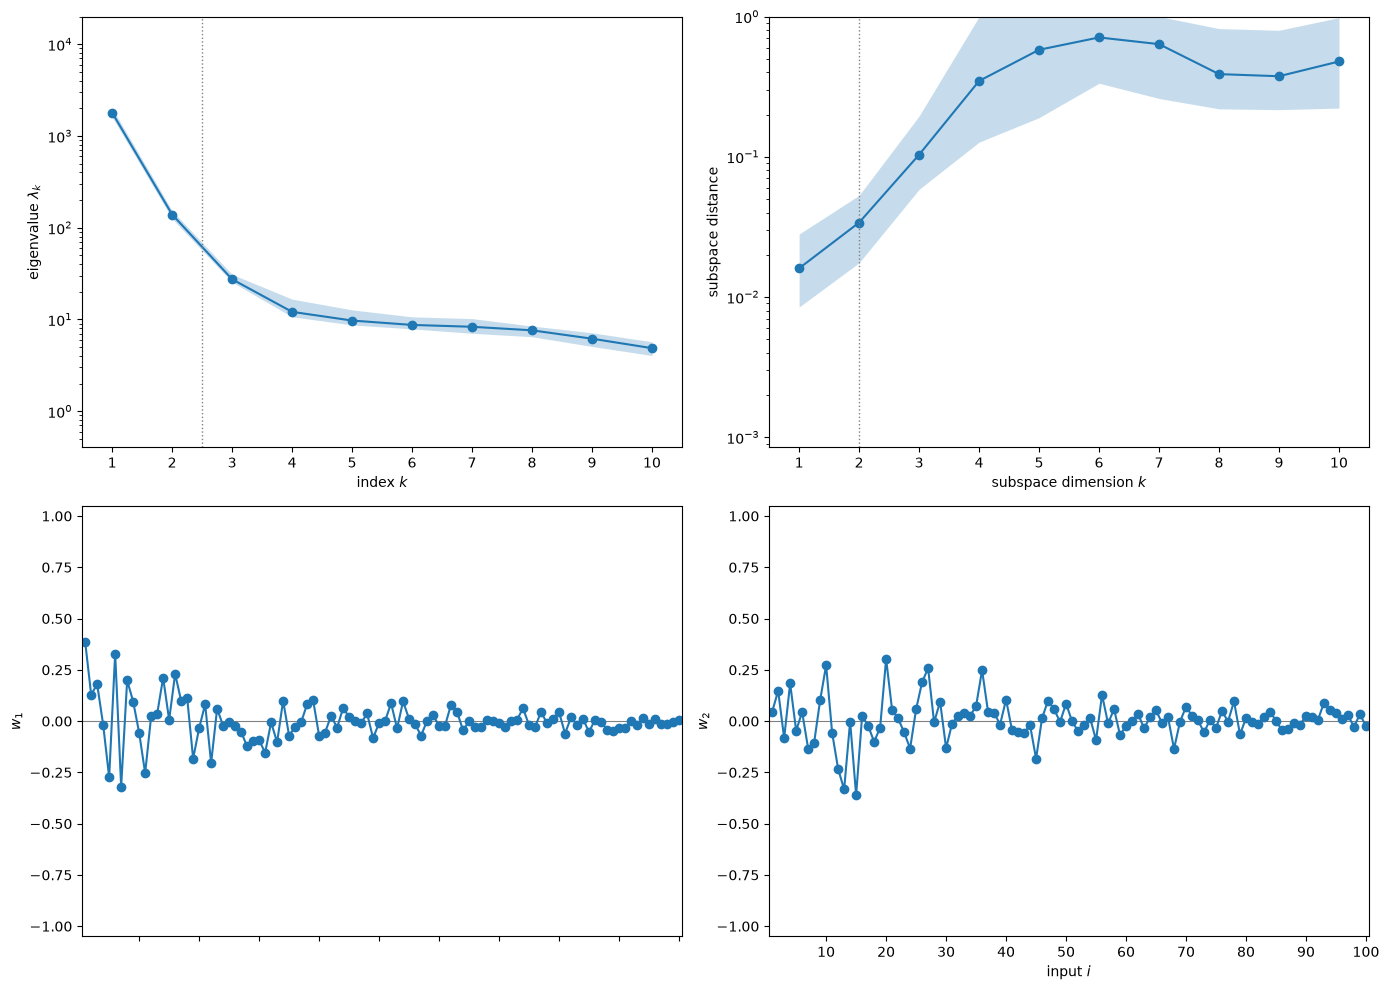

In [9]:
space = ac.Gaussian.reference(100)
sub_default = ac.active_subspace(space=space, grads=z['G'])
sub = ac.active_subspace(space=space, grads=z['G'], nboot=100, rng=rng, n=2)
sub = ac.orient(sub, by='reference', reference=np.eye(100)[:, [0, 0]], columns=2)
lam = sub.eigenvalues
W = z['W']
print(f'default rule: n = {sub_default.n}; chosen: n = {sub.n}')
print(f'eigenvalues 1-4: {np.round(lam[:4], 1)}; ratios lambda_1/lambda_2 = {lam[0] / lam[1]:.1f}, '
      f'lambda_2/lambda_3 = {lam[1] / lam[2]:.1f}')
print(f'|cos| between recomputed and stored w1, w2: '
      f'{np.abs(np.sum(sub.W[:, :2] * W[:, :2], axis=0))}; '
      f'||W1^T W1 - I|| = {np.linalg.norm(W[:, :2].T @ W[:, :2] - np.eye(2)):.1e}')

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
ac.plotting.plot_eigenvalues(sub, k_max=10, interval='minmax', ax=axes[0, 0])
ac.plotting.plot_subspace_errors(sub, k_max=10, interval='minmax', ax=axes[0, 1])
ac.plotting.plot_eigenvectors(sub, indices=[0, 1], ax=[axes[1, 0], axes[1, 1]])
fig.tight_layout()
plt.show()

We find gaps after the first and the second eigenvalues (the ratios are printed above) and small bootstrap subspace errors for one and two dimensions, as in [[1]][R1] Fig. 5.5, so we use a two-dimensional active subspace. Like [[1]][R1] Fig. 5.6(a)–(b), the eigenvectors put most of their weight on the leading Karhunen–Loève coefficients. The recomputed eigenvectors equal the stored ones.

The 100 inputs have little physical meaning by themselves, but we can examine sensitivity by plugging an eigenvector into $\mathbf x$ in the Karhunen–Loève series: $\sum_i \sqrt{\sigma_i}\,\phi_i(\mathbf s)\,w_{ij}$ is the perturbation of the log-coefficient $\log(a)$ along $\mathbf w_j$, as in [[1]][R1] Fig. 5.6. We plot it for the first two eigenvectors, with the sensor locations as dots.

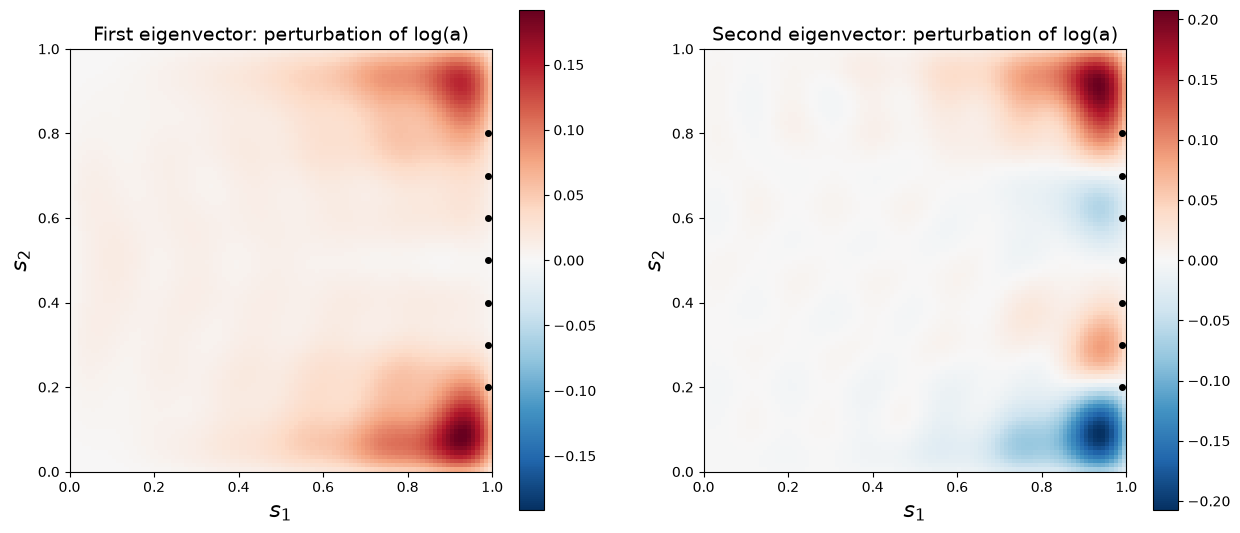

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for j, ax in enumerate(axes):
    field = (model.B @ W[:, j]).reshape(model.nx, model.nx)   # rows: s2, columns: s1
    vmax = np.abs(field).max()
    im = ax.imshow(field, origin='lower', extent=[0, 1, 0, 1], cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    ax.plot(z['sensor_s1'], z['sensor_s2'], 'ko', ms=4)
    ax.set_xlabel(r'$s_1$', fontsize=16); ax.set_ylabel(r'$s_2$', fontsize=16)
    ax.set_title(['First', 'Second'][j] + ' eigenvector: perturbation of log(a)', fontsize=14)
    fig.colorbar(im, ax=ax)
plt.show()

As in [[1]][R1] Fig. 5.6(c)–(d), the misfit is most sensitive to the coefficient near the right boundary, where the observations are, and most of all near its top and bottom corners. The second eigenvector contrasts the bottom corner with the top one.

### The stored chains

`generate_data.py` ran 100,000 steps of vanilla MCMC on all 100 parameters, and 10,000 steps of Metropolis-Hastings on the two active variables with $\hat g_\varepsilon$ ($M = 10$) recomputed at the current state and at the proposal at every step, the 2016 variant described above. The vanilla chain uses $10^5$ forward model evaluations and the active-variable chain $2\times 10^5$; [[1]][R1] Table 5.1 counts $M$ evaluations per step for the latter. Both proposals are Gaussian with standard deviation 0.1 in each coordinate. [[1]][R1] ran 500k and 50k steps; the stored chains are 5 times shorter.

Every random draw of a chain comes from its own seeded stream, one step at a time, so a shorter run reproduces the start of a longer one. Before using the stored chains, we rerun the first 1000 vanilla steps and the first 100 active-variable steps here with the generator's code and seeds (about a minute and a half) and compare them with the stored chains.

In [11]:
t0 = time.perf_counter()
streams = generate_data.streams(int(z['seed']))
van_live = generate_data.run_vanilla(model.d, model.sig2, W, streams['vanilla'], N=1000)
av_live = generate_data.run_active(model.d, model.sig2, W, streams['active'], N=100)
print(f'reran in {time.perf_counter() - t0:.0f} s')
for name, live, n in [('vanilla x_10, x_90', 'van_trace', 1000), ('vanilla misfit', 'van_misfit', 1000),
                      ('active y', 'av_y', 100), ('active ghat', 'av_ghat', 100)]:
    src = van_live if name.startswith('vanilla') else av_live
    print(f'{name:>18}: max |live - stored| = {np.max(np.abs(src[live] - z[live][:n])):.1e}')
print(f'acceptance flags equal: vanilla {np.array_equal(van_live["van_accept"], z["van_accept"][:1000])}, '
      f'active {np.array_equal(av_live["av_accept"], z["av_accept"][:100])}')

reran in 66 s
vanilla x_10, x_90: max |live - stored| = 0.0e+00
    vanilla misfit: max |live - stored| = 0.0e+00
          active y: max |live - stored| = 0.0e+00
       active ghat: max |live - stored| = 0.0e+00
acceptance flags equal: vanilla True, active True


Now we load the full chains. As in [[1]][R1], we discard the first 20% of each chain as burn-in: 20,000 vanilla steps and 2,000 active-variable steps. For each remaining $\hat{\mathbf y}_k$ we draw $P = 10$ samples of the 98 inactive variables from the prior and reconstruct $\mathbf x_{k,l} = \hat{\mathbf W}_1\hat{\mathbf y}_k + \hat{\mathbf W}_2\hat{\mathbf z}_{k,l}$, using the stored $\hat{\mathbf W}$.

vanilla: 100000 steps, acceptance rate 0.5460 (paper: 60%)
active subspace: 10000 steps, acceptance rate 0.6095 (paper, n = 2 and proposal standard deviation 0.1: 62%)
burn-in: 20000 vanilla steps, 2000 active-variable steps


20 estimates ghat(y) with M = 10 at the posterior mean of y: mean 10.43, standard deviation 1.57


reconstructed x: 80000 samples


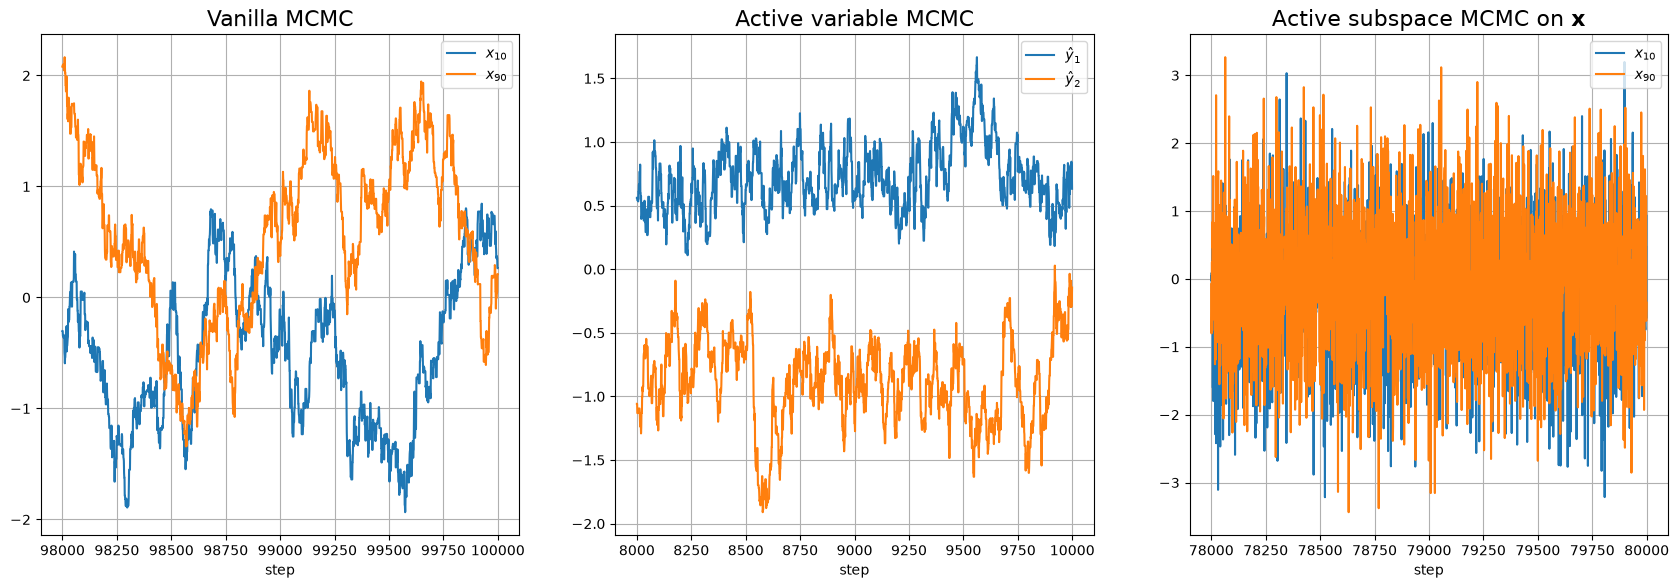

In [12]:
N_van, N_av = len(z['van_accept']), len(z['av_accept'])
b_van, b_av = int(z['burn_in'] * N_van), int(z['burn_in'] * N_av)
print(f'vanilla: {N_van} steps, acceptance rate {z["van_accept"].mean():.4f} (paper: 60%)')
print(f'active subspace: {N_av} steps, acceptance rate {z["av_accept"].mean():.4f} '
      f'(paper, n = 2 and proposal standard deviation 0.1: 62%)')
print(f'burn-in: {b_van} vanilla steps, {b_av} active-variable steps')
y_mean = z['av_y'][b_av:].mean(axis=0)
g_rep = [ActiveSubspaceMCMC(model.misfit, W[:, :2], W[:, 2:]).ghat(y_mean, 10, rng) for _ in range(20)]
print(f'20 estimates ghat(y) with M = 10 at the posterior mean of y: mean {np.mean(g_rep):.2f}, '
      f'standard deviation {np.std(g_rep, ddof=1):.2f}')

Y = z['av_y'][b_av:]
pde_sampler = ActiveSubspaceMCMC(model.misfit, W[:, :2], W[:, 2:])
P = 10
X_as = pde_sampler.sample_original_variables(Y, P, rng)
print(f'reconstructed x: {X_as.shape[0]} samples')

TP_N = min(2000, N_av)   # steps shown in the trace plots
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
k = np.arange(N_van - TP_N, N_van)
axes[0].plot(k, z['van_trace'][k, 0], k, z['van_trace'][k, 1])
axes[0].set_title('Vanilla MCMC', fontsize=16)
axes[0].legend([r'$x_{10}$', r'$x_{90}$'])
k = np.arange(N_av - TP_N, N_av)
axes[1].plot(k, z['av_y'][k, 0], k, z['av_y'][k, 1])
axes[1].set_title('Active variable MCMC', fontsize=16)
axes[1].legend([r'$\hat y_1$', r'$\hat y_2$'])
k = np.arange(len(X_as) - TP_N, len(X_as))
axes[2].plot(k, X_as[k, 9], k, X_as[k, 89])
axes[2].set_title(r'Active subspace MCMC on $\mathbf{x}$', fontsize=16)
axes[2].legend([r'$x_{10}$', r'$x_{90}$'])
for ax in axes:
    ax.grid(True); ax.set_xlabel('step')
plt.show()

The vanilla acceptance rate is close to [[1]][R1]'s 60%, and the active-variable chain's is close to [[1]][R1]'s 62%; both proposals have standard deviation 0.1. With $M = 10$, the estimates $\hat g_\varepsilon$ at the posterior mean of $\hat{\mathbf y}$ have a standard deviation of 1.57 (printed above), so the acceptance test of every step sees new noise. Algorithm 1 as printed, run with the same data, $\hat{\mathbf W}$ and seed, accepts far fewer proposals, because a state whose estimate came out low keeps it (see `DATA.md`).

As for the quadratic model, the vanilla chain on $\mathbf x$ moves slowly, while the $\mathbf x$ reconstructed from the active-variable chain looks like independent draws ([[1]][R1] Fig. 5.8), because 98 of its 100 directions are drawn independently from the prior.

To compare the chains, we consider the variables $\hat{\mathbf y}_k = \hat{\mathbf W}^T\mathbf x_k$, where $\mathbf x_k$ are the states of the vanilla 100-dimensional chain (`generate_data.py` stores the first four components for every step). If the two-dimensional structure is real, the posterior marginals of the first two components should depart most from the standard Gaussian prior, because the data update them ([[1]][R1] Fig. 5.10). First we compare the posterior mean of $\hat y_1, \hat y_2$ from the vanilla chain with the mean of the active-variable chain, with consistent batch-means standard errors [[3]][R3] for both.

The active-variable chain does not sample the posterior, so we also compute, directly, the means of $\hat{\mathbf y}$ under the two densities it approximates:

- $\pi_\varepsilon \propto \exp(-g_\varepsilon(\hat{\mathbf y}))\,\rho_{\text{pri}}(\hat{\mathbf y})$, with the exact conditional mean $g_\varepsilon$;
- $\pi_M \propto \mathbb E\left[\exp(-\hat g_\varepsilon(\hat{\mathbf y}))\right]\rho_{\text{pri}}(\hat{\mathbf y})$, the average over the noise of the estimate with $M = 10$ draws. It lies between $\pi_\varepsilon$ and the posterior marginal of $\hat{\mathbf y}$. Algorithm 1 as printed, which keeps $\hat g_\varepsilon$ with the state, samples $\pi_M$ exactly (it is a pseudo-marginal method). The variant used here, which recomputes $\hat g_\varepsilon$ at every step, is a noisy approximation of it, known as Monte Carlo within Metropolis [[4]][R4]; it has no closed-form stationary density.

We compute both on a $15\times 15$ grid in $\hat{\mathbf y}$ covering four standard deviations of the active-variable chain on each side of its mean, from the same 40 draws of $\hat{\mathbf z}$ at every grid point (about three minutes). For $\pi_M$, the expectation is averaged over 400 random 10-draw subsets of the 40. Each grid mean's standard error is the standard deviation over 200 bootstrap resamples of the 40 draws. We check that the chain's mean agrees with the $\pi_M$ grid mean within $3\,(\mathrm{SE}_{\text{chain}}^2 + \mathrm{SE}_{\text{grid}}^2)^{1/2}$ in each component.

 mean ± SE           vanilla            active   |diff|/SE_van  |diff|/SE_both
       y_1     0.755 ± 0.011     0.667 ± 0.026             7.8             3.1
       y_2    -0.882 ± 0.019    -0.738 ± 0.060             7.5             2.3
vanilla posterior means of y_1..y_4: [ 0.75 -0.88 -1.26  0.01], standard deviations: [0.24 0.37 0.53 0.93]
active-variable chain standard deviations of y_1, y_2: [0.28 0.45]
lambda_1 + lambda_2 = 1934; lambda_3 + ... + lambda_100 = 124


grid: 175 s
             mean of y             y_1             y_2
   vanilla (posterior)    0.755 ± 0.011   -0.882 ± 0.019
         pi_eps (grid)    0.618 ± 0.022   -0.527 ± 0.032
   pi_M, M = 10 (grid)    0.632 ± 0.023   -0.559 ± 0.028
          active chain    0.667 ± 0.026   -0.738 ± 0.060
y_1: |active chain - pi_M| = 0.035, tolerance 3 (SE_chain^2 + SE_grid^2)^(1/2) = 0.105: within
y_2: |active chain - pi_M| = 0.179, tolerance 3 (SE_chain^2 + SE_grid^2)^(1/2) = 0.199: within


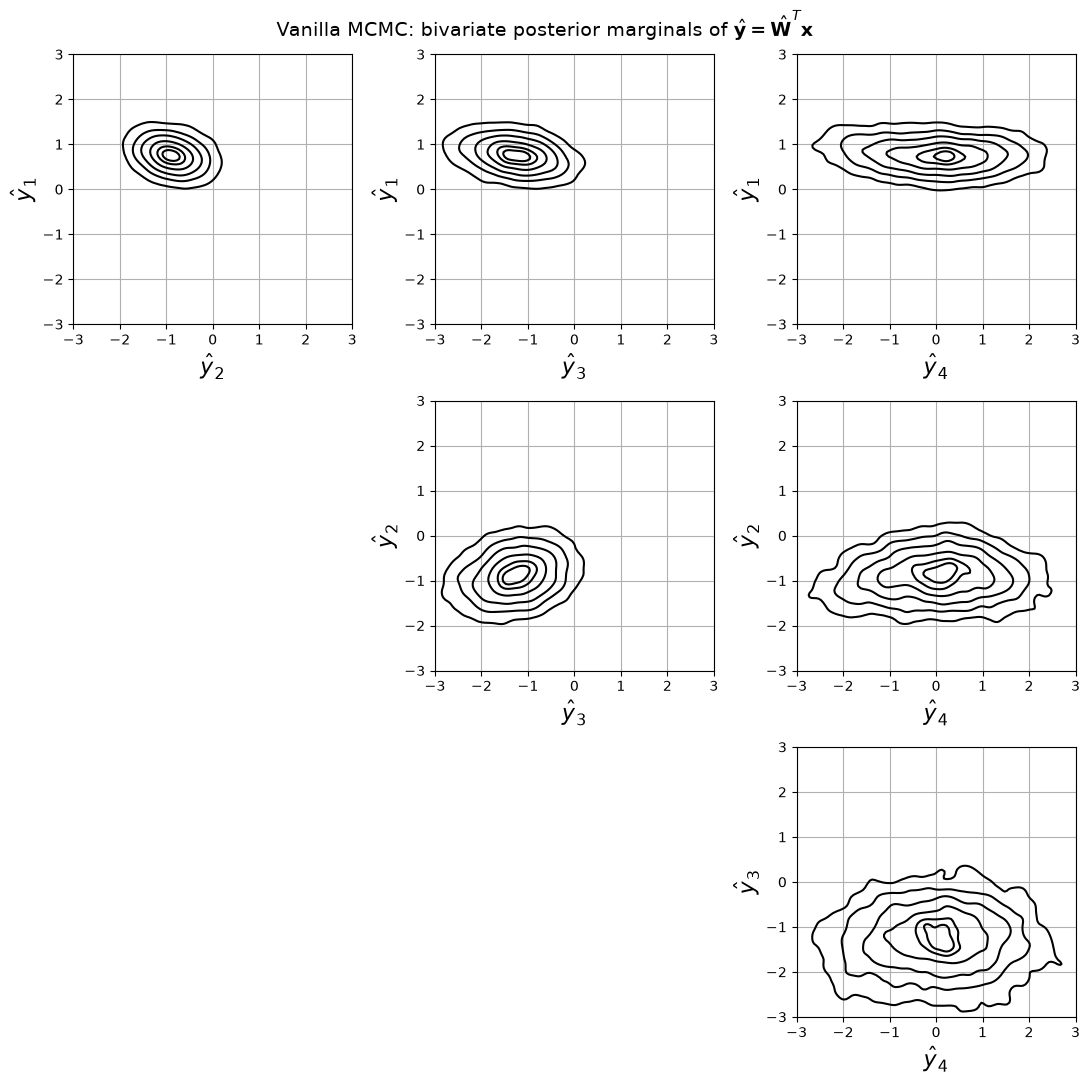

In [13]:
y_van = z['van_proj'][b_van:].astype(float)     # W^T x, first four components
se_van, se_av = batch_means_se(y_van[:, :2]), batch_means_se(Y)
print(f'{"mean ± SE":>10}{"vanilla":>18}{"active":>18}{"|diff|/SE_van":>16}{"|diff|/SE_both":>16}')
for j in range(2):
    diff = abs(y_van[:, j].mean() - Y[:, j].mean())
    print(f'{"y_" + str(j + 1):>10}{y_van[:, j].mean():10.3f} ± {se_van[j]:.3f}'
          f'{Y[:, j].mean():10.3f} ± {se_av[j]:.3f}{diff / se_van[j]:16.1f}'
          f'{diff / np.hypot(se_van[j], se_av[j]):16.1f}')
print(f'vanilla posterior means of y_1..y_4: {np.round(y_van.mean(axis=0), 2)}, '
      f'standard deviations: {np.round(y_van.std(axis=0), 2)}')
print(f'active-variable chain standard deviations of y_1, y_2: {np.round(Y.std(axis=0), 2)}')
print(f'lambda_1 + lambda_2 = {lam[:2].sum():.0f}; lambda_3 + ... + lambda_100 = {lam[2:].sum():.0f}')

# the mean of y under pi_eps on a grid; g_eps(y) from the same 40 draws of z at every grid point
m_y, s_y = Y.mean(axis=0), Y.std(axis=0)
g1, g2 = [np.linspace(m_y[j] - 4*s_y[j], m_y[j] + 4*s_y[j], 15) for j in range(2)]
G1, G2 = np.meshgrid(g1, g2, indexing='ij')
Z_grid = rng.standard_normal((40, 98))
t0 = time.perf_counter()
f_grid = np.array([[[model.misfit(W[:, :2] @ np.array([a, b]) + W[:, 2:] @ zz) for zz in Z_grid]
                     for b in g2] for a in g1])                      # (15, 15, 40)


def grid_mean(loglik):
    """Mean of y under exp(loglik(y)) rho(y) on the grid."""
    log_pi = loglik - 0.5*(G1**2 + G2**2)
    p = np.exp(log_pi - log_pi.max())
    p /= p.sum()
    return np.array([(p*G1).sum(), (p*G2).sum()])


def loglik_eps(F):
    """log exp(-g_eps), g_eps the mean over the draws."""
    return -F.mean(axis=2)


def loglik_M(F, n_sub=400):
    """log E[exp(-ghat)] for ghat from M = 10 draws: average over random 10-draw subsets."""
    S = np.array([rng.choice(F.shape[2], 10, replace=False) for _ in range(n_sub)])
    g = F[:, :, S].mean(axis=3)
    g0 = g.min(axis=2, keepdims=True)
    return -g0[..., 0] + np.log(np.exp(-(g - g0)).mean(axis=2))


refs = {}
for name, loglik in [('pi_eps', loglik_eps), ('pi_M, M = 10', loglik_M)]:
    boot = np.array([grid_mean(loglik(f_grid[:, :, rng.integers(0, 40, 40)])) for _ in range(200)])
    refs[name] = grid_mean(loglik(f_grid)), boot.std(axis=0, ddof=1)
print(f'grid: {time.perf_counter() - t0:.0f} s')
print(f'{"mean of y":>22}{"y_1":>16}{"y_2":>16}')
rows = [('vanilla (posterior)', y_van[:, :2].mean(axis=0), se_van)] + \
       [(f'{k} (grid)', m, s) for k, (m, s) in refs.items()] + [('active chain', Y.mean(axis=0), se_av)]
for name, mean, se in rows:
    print(f'{name:>22}' + ''.join(f'{mean[j]:9.3f} ± {se[j]:.3f}' for j in range(2)))
m_M, se_M = refs['pi_M, M = 10']
tol = 3*np.hypot(se_av, se_M)
for j in range(2):
    diff = abs(Y[:, j].mean() - m_M[j])
    print(f'y_{j + 1}: |active chain - pi_M| = {diff:.3f}, tolerance 3 (SE_chain^2 + SE_grid^2)^(1/2) = '
          f'{tol[j]:.3f}: {"within" if diff <= tol[j] else "outside"}')

fig, axes = plt.subplots(3, 3, figsize=(11, 11))
lims = [(-3, 3), (-3, 3)]
for i in range(3):
    for j in range(3):
        ax = axes[i, j]
        if j < i:
            ax.axis('off')
            continue
        (cx, cy), dens = density(y_van[:, [j + 1, i]], lims, .05, .1)
        ax.contour(cx, cy, dens.T, levels=dens.max()*LEVELS, colors="k")
        ax.set_xlim(*lims[0]); ax.set_ylim(*lims[1])
        ax.grid(True)
        ax.set_xlabel(rf'$\hat y_{j + 2}$', fontsize=16); ax.set_ylabel(rf'$\hat y_{i + 1}$', fontsize=16)
fig.suptitle(r'Vanilla MCMC: bivariate posterior marginals of $\hat{\mathbf{y}} = \hat{\mathbf{W}}^T\mathbf{x}$', fontsize=14)
fig.tight_layout()
plt.show()

The data move and narrow $\hat y_1$ and $\hat y_2$ the most: their vanilla posterior standard deviations are 0.24 and 0.37, against 1 under the prior. $\hat y_3$ is also shifted and narrowed (mean −1.26, standard deviation 0.53), and $\hat y_4$ stays close to its prior (mean 0.01, standard deviation 0.93).

The posterior means of $\hat y_1, \hat y_2$ from the two chains differ by about 0.09 and 0.14, more than three batch-means standard errors of the vanilla chain plus those of the active-variable chain in $\hat y_1$, so the difference is not only sampling noise. Most of it comes from the approximation. The densities that the active-variable chain approximates, $\pi_\varepsilon$ and $\pi_M$, put the mean of $\hat{\mathbf y}$ farther still from the vanilla mean (the grid table above), because the inactive eigenvalues, $\lambda_3+\cdots+\lambda_{100} = 124$, are not small (they enter the error bound of Theorem 3.1). The chain agrees with $\pi_M$ within the tolerance in both components, but in $\hat y_2$ it is near the edge, shifted from $\pi_M$ toward the posterior (the check above). Its spread is also wider than the vanilla chain's (standard deviations printed above). Both are what one expects from recomputing the noisy $\hat g_\varepsilon$ at every step: the noise in the acceptance test lets the chain move to states that $\pi_M$ weights less.

Finally, as in [[1]][R1] Fig. 5.9, we compare the posterior mean and variance of each of the 100 components of $\mathbf x$ from the reconstructed active subspace chain with those of the vanilla chain. The vanilla moments come from every 10th state (stored by `generate_data.py`), and their 99% confidence intervals from consistent batch means; we plot the differences, centered at the vanilla values.

components whose active subspace mean lies in the vanilla 99% interval: 79%; variance: 93%


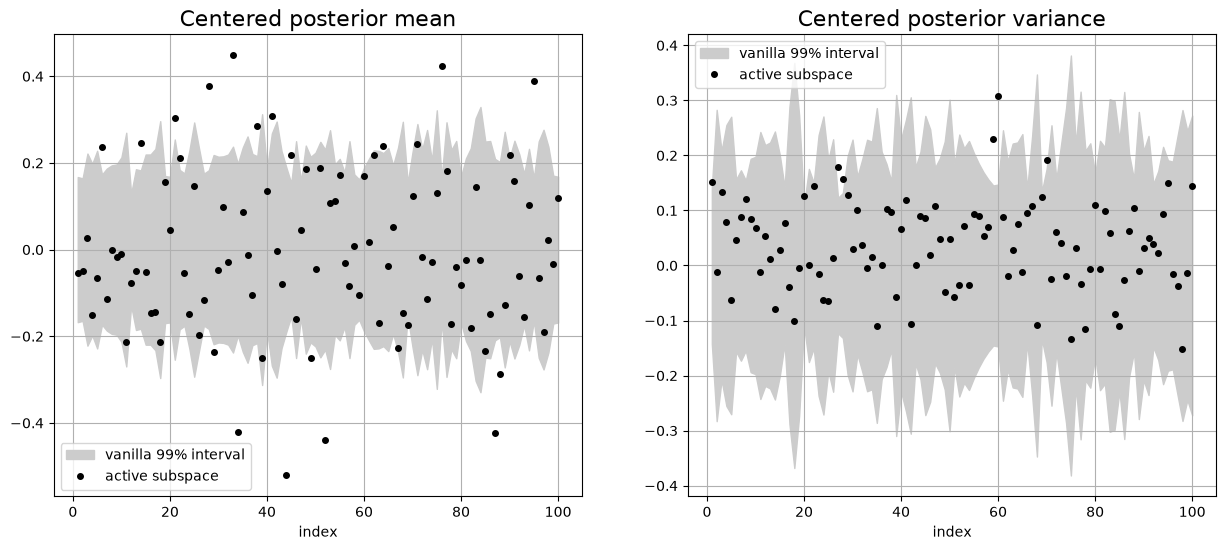

In [14]:
X_thin = z['van_thin'][b_van // int(z['thin']):].astype(float)
mu_van, var_van = X_thin.mean(axis=0), X_thin.var(axis=0)
mu_as, var_as = X_as.mean(axis=0), X_as.var(axis=0)
q = 2.576   # 99% normal quantile
hw_mu = q * batch_means_se(X_thin)
hw_var = q * batch_means_se((X_thin - mu_van)**2)
inside_mu = np.mean(np.abs(mu_as - mu_van) <= hw_mu)
inside_var = np.mean(np.abs(var_as - var_van) <= hw_var)
print(f'components whose active subspace mean lies in the vanilla 99% interval: {inside_mu:.0%}; '
      f'variance: {inside_var:.0%}')

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
idx = np.arange(1, 101)
for ax, diff, hw, name in [(axes[0], mu_as - mu_van, hw_mu, 'mean'),
                           (axes[1], var_as - var_van, hw_var, 'variance')]:
    ax.fill_between(idx, -hw, hw, color='0.8', label='vanilla 99% interval')
    ax.plot(idx, diff, 'ko', ms=4, label='active subspace')
    ax.grid(True); ax.legend()
    ax.set_xlabel('index'); ax.set_title(f'Centered posterior {name}', fontsize=16)
plt.show()

For 79% of the 100 components, the posterior mean from the active subspace chain lies in the vanilla 99% interval, and for 93% the variance does. As in [[1]][R1] Fig. 5.9, the bulk of the points lies in the intervals; those outside reflect the bias of $\hat\pi_\varepsilon$ seen above. The vanilla intervals are wide because the vanilla chain mixes slowly in $\mathbf x$.

We have shown for two forward models that reducing their dimensionality with active subspaces significantly improves the mixing of the resulting Markov chains, for the same number of forward model evaluations. The price is the error of the approximate posterior, which is small when the eigenvalues after the gap are small. This methodology could potentially be used to increase computational efficiency in many Bayesian inverse problems.

In [15]:
print(f'Total run time: {time.perf_counter() - t_start:.0f} s')

Total run time: 270 s
